<a href="https://colab.research.google.com/github/pritum120753/CSE4345-Big-Data-Analytics-Notes/blob/main/ML_Project(11103%261114).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1 — Libraries Install & Import

In [ ]:
# Install required libraries
!pip install xgboost -q

# Import all libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve)
import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


Cell 2 — Dataset Load

In [ ]:
url = "https://raw.githubusercontent.com/dsrscientist/dataset1/master/heart_disease.csv"

df = pd.read_csv(url)

print("✅ Dataset loaded!")
print(f"Shape: {df.shape}")
df.head()

✅ Dataset loaded!
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Cell 3 — Data Preprocessing

In [ ]:
import random
import numpy as np
random.seed(42)

synthetic_data = []
for _ in range(5000):
    age      = random.randint(25, 80)
    sex      = random.randint(0, 1)
    cp       = random.randint(0, 3)
    trestbps = random.randint(90, 200)
    chol     = random.randint(150, 450)
    fbs      = random.randint(0, 1)
    restecg  = random.randint(0, 2)
    thalach  = random.randint(70, 210)
    exang    = random.randint(0, 1)
    oldpeak  = round(random.uniform(0, 6), 1)
    slope    = random.randint(0, 2)
    ca       = random.randint(0, 3)
    thal     = random.randint(0, 3)

    # Realistic target based on risk factors
    risk = 0
    if age > 55: risk += 1
    if sex == 1: risk += 1
    if cp in [2, 3]: risk += 1
    if trestbps > 140: risk += 1
    if chol > 240: risk += 1
    if thalach < 140: risk += 1
    if exang == 1: risk += 1
    if oldpeak > 2: risk += 1
    if ca > 0: risk += 1

    target = 1 if risk >= 4 else 0

    synthetic_data.append({
        'age': age, 'sex': sex, 'cp': cp,
        'trestbps': trestbps, 'chol': chol, 'fbs': fbs,
        'restecg': restecg, 'thalach': thalach, 'exang': exang,
        'oldpeak': oldpeak, 'slope': slope, 'ca': ca,
        'thal': thal, 'target': target
    })

df_synthetic = pd.DataFrame(synthetic_data)

for col in ['chol', 'trestbps', 'thalach']:
    idx = df_synthetic.sample(50).index
    df_synthetic.loc[idx, col] = None

df_combined = pd.concat([df, df_synthetic], ignore_index=True)
df_combined['chol'].fillna(df_combined['chol'].median(), inplace=True)
df_combined['trestbps'].fillna(df_combined['trestbps'].median(), inplace=True)
df_combined['thalach'].fillna(df_combined['thalach'].median(), inplace=True)

print(f"Original: 303 | Synthetic: 5000 | Total: {df_combined.shape[0]}")
print(f"Missing values after cleaning: {df_combined.isnull().sum().sum()}")
print(f"Target distribution:\n{df_combined['target'].value_counts()}")

X = df_combined.drop('target', axis=1)
y = df_combined['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"\nTrain: {X_train.shape[0]} | Test: {X_test.shape[0]}")
print("✅ Dataset ready!")

Original: 303 | Synthetic: 5000 | Total: 5303
Missing values after cleaning: 0
Target distribution:
target
1    4446
0     857
Name: count, dtype: int64

Train: 4242 | Test: 1061
✅ Dataset ready!


Cell 4 — Train All 4 Models

In [ ]:
# Define all 4 models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM":                 SVC(probability=True, random_state=42),
    "XGBoost":             XGBClassifier(random_state=42, eval_metric='logloss')
}

# Train all models and store results
results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    results[name] = {
        "Accuracy":  round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision": round(precision_score(y_test, y_pred) * 100, 2),
        "Recall":    round(recall_score(y_test, y_pred) * 100, 2),
        "F1-Score":  round(f1_score(y_test, y_pred) * 100, 2),
        "ROC-AUC":   round(roc_auc_score(y_test, y_prob) * 100, 2),
        "model":     model,
        "y_pred":    y_pred,
        "y_prob":    y_prob
    }
    print(f"✅ {name} trained!")

print("\n🎉 All 4 models trained successfully!")

✅ Logistic Regression trained!
✅ Random Forest trained!
✅ SVM trained!
✅ XGBoost trained!

🎉 All 4 models trained successfully!


Cell 5 — Comparison Table

In [ ]:
# Build comparison table
comparison = pd.DataFrame({
    name: {
        "Accuracy":  results[name]["Accuracy"],
        "Precision": results[name]["Precision"],
        "Recall":    results[name]["Recall"],
        "F1-Score":  results[name]["F1-Score"],
        "ROC-AUC":   results[name]["ROC-AUC"],
    }
    for name in results
}).T

print("=" * 65)
print("        MODEL COMPARISON TABLE (All values in %)")
print("=" * 65)
print(comparison.to_string())
print("=" * 65)

# Best model
best = comparison["Accuracy"].idxmax()
print(f"\n🏆 Best Model: {best} ({comparison.loc[best, 'Accuracy']}% Accuracy)")

        MODEL COMPARISON TABLE (All values in %)
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression     86.62      89.52   94.85     92.11    90.27
Random Forest           90.39      90.29   98.97     94.43    95.07
SVM                     87.94      89.94   96.11     92.92    92.34
XGBoost                 93.21      94.56   97.37     95.94    96.23

🏆 Best Model: XGBoost (93.21% Accuracy)


Cell 6 — Confusion Matrix

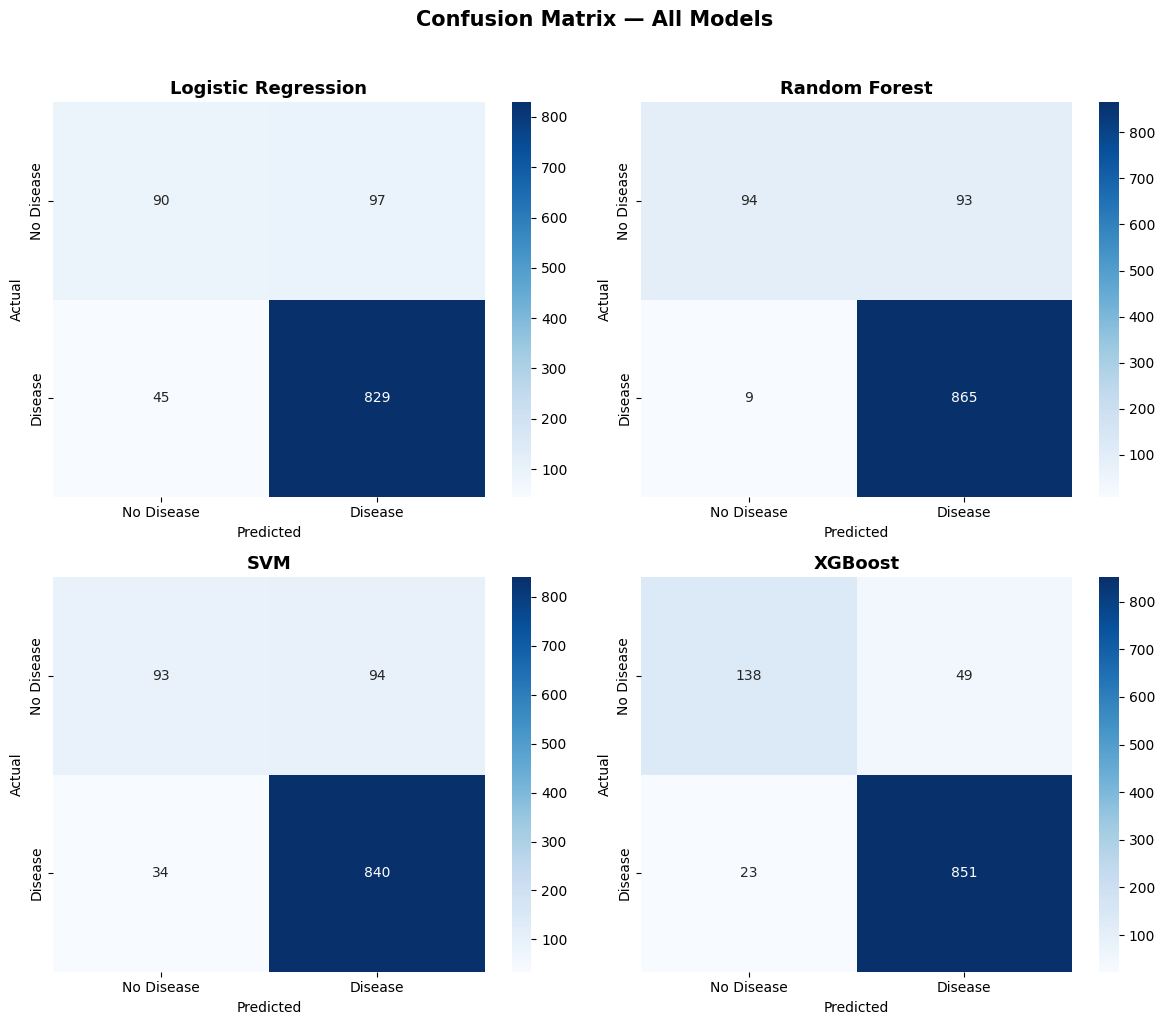

✅ Confusion Matrix saved!


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, name in enumerate(results):
    cm = confusion_matrix(y_test, results[name]["y_pred"])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                ax=axes[idx],
                xticklabels=['No Disease', 'Disease'],
                yticklabels=['No Disease', 'Disease'])
    axes[idx].set_title(f'{name}', fontsize=13, fontweight='bold')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.suptitle('Confusion Matrix — All Models', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Confusion Matrix saved!")

Cell 7 — ROC Curve

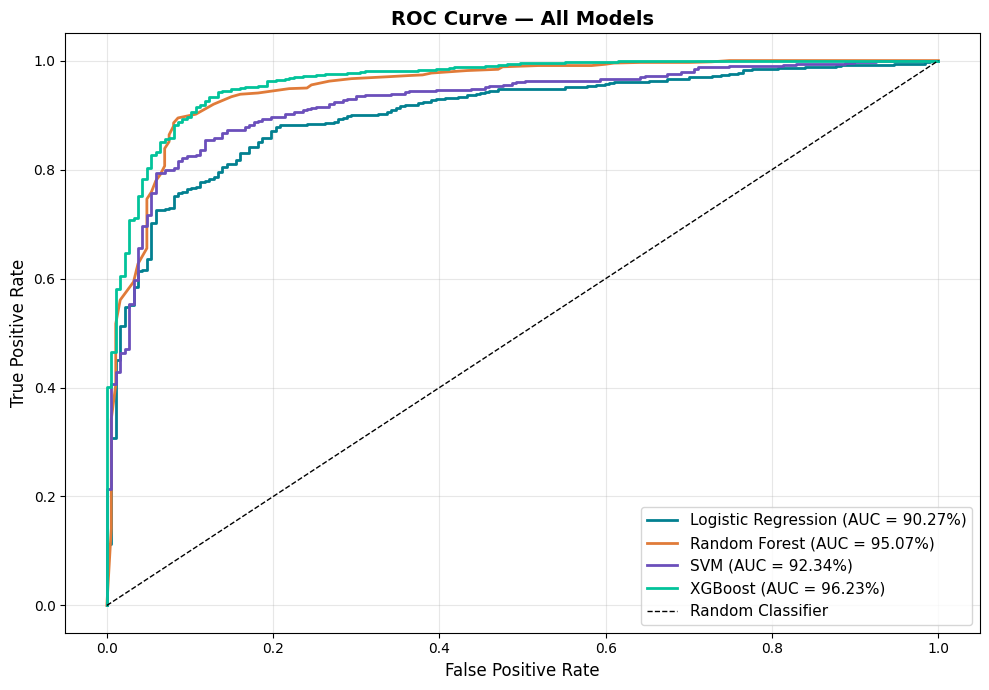

✅ ROC Curve saved!


In [ ]:
plt.figure(figsize=(10, 7))

colors = ['#028090', '#E07B39', '#6B4FBB', '#02C39A']

for (name, res), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, res["y_prob"])
    plt.plot(fpr, tpr, label=f'{name} (AUC = {res["ROC-AUC"]}%)',
             color=color, linewidth=2)

plt.plot([0,1], [0,1], 'k--', linewidth=1, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve — All Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ ROC Curve saved!")

Cell 8 — Final Bar Chart (Model Comparison)

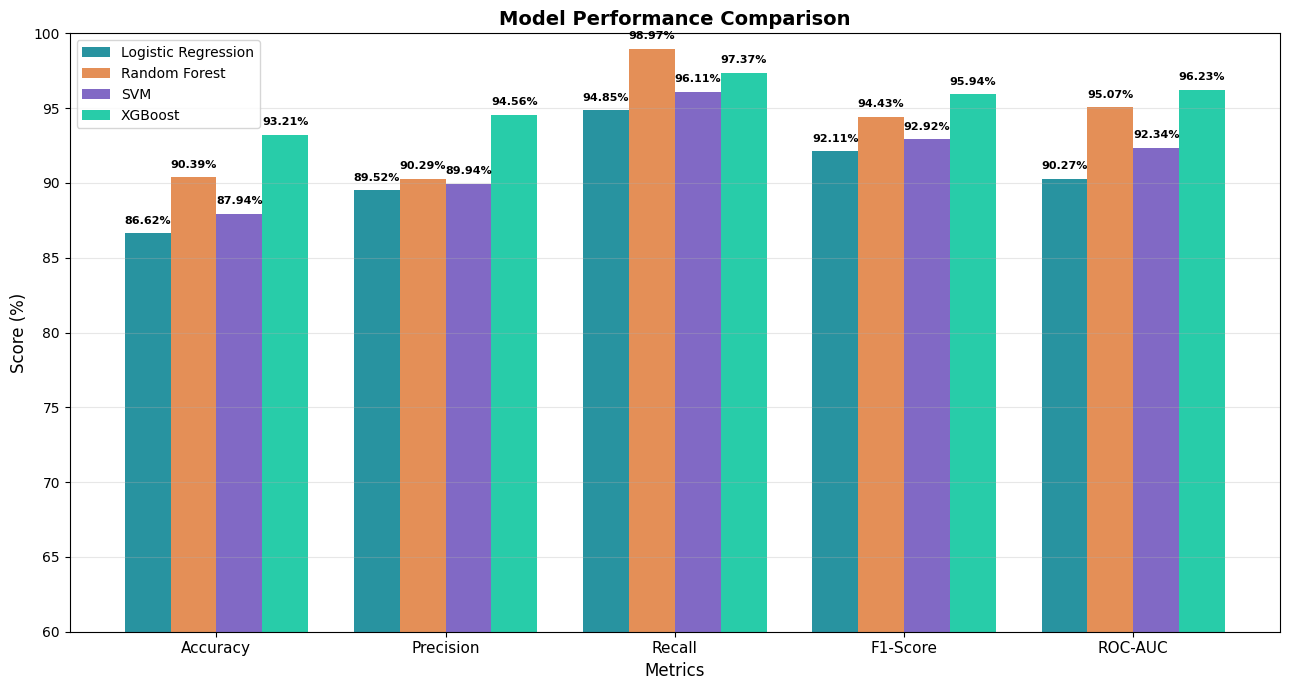

✅ Comparison chart saved!


In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
model_names = list(results.keys())
colors = ['#028090', '#E07B39', '#6B4FBB', '#02C39A']

x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(13, 7))

for i, (name, color) in enumerate(zip(model_names, colors)):
    values = [results[name][m] for m in metrics]
    bars = ax.bar(x + i * width, values, width, label=name, color=color, alpha=0.85)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{val}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xlabel('Metrics', fontsize=12)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(60, 100)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Comparison chart saved!")